In [25]:
import pandas as pd

df = pd.read_csv("/content/CelularesSubtraidos_2023_reduzido.csv", encoding="utf-8")

print(df.columns.tolist())
print(df.shape)
df.head()

['ID_DELEGACIA', 'NOME_MUNICIPIO', 'ANO_BO', 'NUM_BO', 'VERSAO', 'DATA_OCORRENCIA_BO', 'HORA_OCORRENCIA', 'DESCR_PERIODO', 'RUBRICA', 'DESCR_TIPOLOCAL', 'CIDADE', 'BAIRRO', 'LATITUDE', 'LONGITUDE', 'DESCR_TIPO_OBJETO', 'QUANTIDADE_OBJETO', 'MARCA_OBJETO', 'CD_IBGE']
(183704, 18)


,ID_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,DATA_OCORRENCIA_BO,HORA_OCORRENCIA,DESCR_PERIODO,RUBRICA,DESCR_TIPOLOCAL,CIDADE,BAIRRO,LATITUDE,LONGITUDE,DESCR_TIPO_OBJETO,QUANTIDADE_OBJETO,MARCA_OBJETO,CD_IBGE
0,900020,S.PAULO,2023,AA0060,3,2022-01-30 00:00:00,NaN,Pela manhã,Furto (art. 155),Terminal/Estação,S.PAULO,TATUAPÉ,NaN,NaN,Telecomunicação,1,Samsung,3550308
1,900020,S.PAULO,2023,AA0110,2,2022-12-30 00:00:00,NaN,Pela manhã,Furto (art. 155),Terminal/Estação,S.PAULO,BRÁS,NaN,NaN,Telecomunicação,1,Motorola,3550308
2,900020,S.PAULO,2023,AA0383,3,2022-12-30 00:00:00,18:03:00,NaN,Roubo (art. 157),Terminal/Estação,S.PAULO,TATUAPÉ,NaN,NaN,Telecomunicação,1,Samsung,3550308
3,900020,S.PAULO,2023,AA1853,4,2022-10-14 00:00:00,NaN,A tarde,Furto (art. 155),Terminal/Estação,S.PAULO,TATUAPÉ,NaN,NaN,Telecomunicação,1,Xiaomi,3550308
4,900020,S.PAULO,2023,AA4173,3,2022-12-30 00:00:00,NaN,A tarde,Furto (art. 155),Terminal/Estação,S.PAULO,CHÁCARA SEIS DE OUTUBRO,NaN,NaN,Telecomunicação,1,Samsung,3550308


In [26]:
print(df["CIDADE"].value_counts().head(15))
print(df["NOME_MUNICIPIO"].value_counts().head(5))

CIDADE
S.PAULO                109553
GUARULHOS                4037
CAMPINAS                 3973
S.ANDRE                  3816
S.BERNARDO DO CAMPO      3306
OSASCO                   3110
DIADEMA                  2387
GUARUJA                  1902
PRAIA GRANDE             1884
RIBEIRAO PRETO           1807
SOROCABA                 1634
ITAQUAQUECETUBA          1597
MAUA                     1541
SANTOS                   1370
S.VICENTE                1225
Name: count, dtype: int64
NOME_MUNICIPIO
S.PAULO                109553
GUARULHOS                4037
CAMPINAS                 3973
S.ANDRE                  3816
S.BERNARDO DO CAMPO      3306
Name: count, dtype: int64


filtrando

In [27]:
import unicodedata

def normaliza(s):
    s = str(s).strip().upper()
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

df["CIDADE_N"] = df["CIDADE"].map(normaliza)
print(df["CIDADE_N"].value_counts().head(10))   # confira as variações

capital = {"S.PAULO", "SAO PAULO"}              # ajuste conforme o que apareceu acima
df_sp = df[df["CIDADE_N"].isin(capital)].copy()

print(f"Antes: {len(df):,} | Depois: {len(df_sp):,}")

CIDADE_N
S.PAULO                109553
GUARULHOS                4037
CAMPINAS                 3973
S.ANDRE                  3816
S.BERNARDO DO CAMPO      3306
OSASCO                   3110
DIADEMA                  2387
GUARUJA                  1902
PRAIA GRANDE             1884
RIBEIRAO PRETO           1807
Name: count, dtype: int64
Antes: 183,704 | Depois: 109,553


In [28]:
print(df_sp["RUBRICA"].value_counts())

RUBRICA
Roubo (art. 157)    56621
Furto (art. 155)    52932
Name: count, dtype: int64


In [29]:
def rotula(x):
    x = normaliza(x)
    if "ROUBO" in x: return 1
    if "FURTO" in x: return 0
    return None

df_sp["alvo"] = df_sp["RUBRICA"].map(rotula)
df_sp = df_sp.dropna(subset=["alvo"])
print(df_sp["alvo"].value_counts())

alvo
1    56621
0    52932
Name: count, dtype: int64


removendo duplicatas

In [30]:
print(df_sp["NUM_BO"].duplicated().sum())

17675


In [31]:
def rotula(x):
    x = normaliza(x)
    if "ROUBO" in x: return 1
    if "FURTO" in x: return 0
    return None

df_sp["alvo"] = df_sp["RUBRICA"].map(rotula)
df_sp = df_sp.dropna(subset=["alvo"])

# duplicidades de boletim
print("Duplicados:", df_sp.duplicated(subset=["ID_DELEGACIA", "NUM_BO", "ANO_BO"]).sum())
df_sp = df_sp.drop_duplicates(subset=["ID_DELEGACIA", "NUM_BO", "ANO_BO"])

print(df_sp["alvo"].value_counts())
print(len(df_sp))

Duplicados: 17675
alvo
0    50402
1    41476
Name: count, dtype: int64
91878


In [32]:
df_sp = df_sp.drop_duplicates(subset=["ID_DELEGACIA", "NUM_BO", "ANO_BO"])

In [33]:
import pandas as pd
import unicodedata

def normaliza(s):
    s = str(s).strip().upper()
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

# 1. Valores da coluna CIDADE (local do fato)
df["CIDADE_N"] = df["CIDADE"].map(normaliza)
print("=== CIDADE_N ===")
print(df["CIDADE_N"].value_counts().head(10))

# 2. Filtro da capital
capital = {"S.PAULO", "SAO PAULO"}
df_sp = df[df["CIDADE_N"].isin(capital)].copy()
print(f"\nAntes: {len(df):,} | Depois: {len(df_sp):,}")

# 3. Rubricas existentes na capital
print("\n=== RUBRICA ===")
print(df_sp["RUBRICA"].value_counts())

# 4. Proporção de valores vazios (0.10 = 10% vazio)
print("\n=== % de vazios ===")
print(df_sp[["HORA_OCORRENCIA", "DESCR_PERIODO", "BAIRRO", "DESCR_TIPOLOCAL"]].isna().mean())

=== CIDADE_N ===
CIDADE_N
S.PAULO                109553
GUARULHOS                4037
CAMPINAS                 3973
S.ANDRE                  3816
S.BERNARDO DO CAMPO      3306
OSASCO                   3110
DIADEMA                  2387
GUARUJA                  1902
PRAIA GRANDE             1884
RIBEIRAO PRETO           1807
Name: count, dtype: int64

Antes: 183,704 | Depois: 109,553

=== RUBRICA ===
RUBRICA
Roubo (art. 157)    56621
Furto (art. 155)    52932
Name: count, dtype: int64

=== % de vazios ===
HORA_OCORRENCIA    0.384106
DESCR_PERIODO      0.615894
BAIRRO             0.003514
DESCR_TIPOLOCAL    0.052532
dtype: float64


quando ocorreu o crime

In [34]:
print(df_sp["DESCR_PERIODO"].value_counts(dropna=False))
print(df_sp["HORA_OCORRENCIA"].head(10))

DESCR_PERIODO
NaN                67473
A noite            12563
A tarde            12223
Pela manhã         10758
De madrugada        6004
Em hora incerta      532
Name: count, dtype: int64
0         NaN
1         NaN
2    18:03:00
3         NaN
4         NaN
5    14:30:00
6    14:00:00
7    23:00:00
8         NaN
9         NaN
Name: HORA_OCORRENCIA, dtype: object


In [35]:
sem_horario = df_sp["HORA_OCORRENCIA"].isna() & df_sp["DESCR_PERIODO"].isna()
print("Sem hora e sem período:", sem_horario.sum(), f"({sem_horario.mean():.1%})")

Sem hora e sem período: 0 (0.0%)


tratamento dos dados: Carregar, filtrar a capital, criar o alvo e remover duplicados

In [36]:
import pandas as pd
import numpy as np
import unicodedata

df = pd.read_csv("/content/CelularesSubtraidos_2023_reduzido.csv", encoding="utf-8")

def normaliza(s):
    s = str(s).strip().upper()
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

# recorte da capital (local do fato)
df["CIDADE_N"] = df["CIDADE"].map(normaliza)
df_sp = df[df["CIDADE_N"].isin({"S.PAULO", "SAO PAULO"})].copy()

# rótulo: roubo = 1, furto = 0
def rotula(x):
    x = normaliza(x)
    if "ROUBO" in x: return 1
    if "FURTO" in x: return 0
    return None

df_sp["alvo"] = df_sp["RUBRICA"].map(rotula)
df_sp = df_sp.dropna(subset=["alvo"])

# duplicados
df_sp = df_sp.drop_duplicates(subset=["ID_DELEGACIA", "NUM_BO", "ANO_BO"])
print(len(df_sp))                 # deve dar 91878
print(df_sp["alvo"].value_counts())

91878
alvo
0    50402
1    41476
Name: count, dtype: int64


In [37]:
def periodo(row):
    h = row["HORA_OCORRENCIA"]
    if pd.notna(h):
        try:
            hora = int(str(h).split(":")[0])
            if 0 <= hora < 6:   return "madrugada"
            if 6 <= hora < 12:  return "manha"
            if 12 <= hora < 18: return "tarde"
            return "noite"
        except ValueError:
            pass
    p = normaliza(row["DESCR_PERIODO"]) if pd.notna(row["DESCR_PERIODO"]) else ""
    if "MADRUGADA" in p: return "madrugada"
    if "MANHA" in p:     return "manha"
    if "TARDE" in p:     return "tarde"
    if "NOITE" in p:     return "noite"
    return "incerto"

df_sp["periodo_dia"] = df_sp.apply(periodo, axis=1)
print(df_sp["periodo_dia"].value_counts())

df_sp["data"] = pd.to_datetime(df_sp["DATA_OCORRENCIA_BO"], errors="coerce")
print("Datas inválidas:", df_sp["data"].isna().sum())

# se houver datas inválidas, descarte
df_sp = df_sp.dropna(subset=["data"]).copy()
df_sp["dia_semana"] = df_sp["data"].dt.dayofweek   # 0=segunda ... 6=domingo

periodo_dia
noite        34057
tarde        23828
manha        20920
madrugada    12831
incerto        242
Name: count, dtype: int64
Datas inválidas: 0


bairro e local

In [38]:
df_sp["BAIRRO"] = df_sp["BAIRRO"].fillna("NAO INFORMADO").map(normaliza)
df_sp["DESCR_TIPOLOCAL"] = df_sp["DESCR_TIPOLOCAL"].fillna("NAO INFORMADO").map(normaliza)

print("Bairros distintos (antes de agrupar):", df_sp["BAIRRO"].nunique())
print("Tipos de local:", df_sp["DESCR_TIPOLOCAL"].nunique())
print(df_sp["DESCR_TIPOLOCAL"].value_counts().head(10))

# agrupa bairros com menos de 100 ocorrências
cont = df_sp["BAIRRO"].value_counts()
raros = cont[cont < 100].index
df_sp["BAIRRO"] = df_sp["BAIRRO"].replace(dict.fromkeys(raros, "OUTROS"))
print("Bairros após agrupar:", df_sp["BAIRRO"].nunique())

Bairros distintos (antes de agrupar): 1469
Tipos de local: 29
DESCR_TIPOLOCAL
VIA PUBLICA               74408
TERMINAL/ESTACAO           8338
NAO INFORMADO              5634
RESIDENCIA                  727
COMERCIO E SERVICOS         504
ESTACIONAMENTO/GARAGEM      481
RESTAURANTE E AFINS         297
RODOVIA/ESTRADA             287
LAZER E RECREACAO           259
SHOPPING CENTER             149
Name: count, dtype: int64
Bairros após agrupar: 124


In [39]:
from sklearn.model_selection import train_test_split

_, df_amostra = train_test_split(
    df_sp, test_size=20000, stratify=df_sp["alvo"], random_state=42)

print(len(df_amostra))
print(df_amostra["alvo"].value_counts(normalize=True))

20000
alvo
0    0.5486
1    0.4514
Name: proportion, dtype: float64


**SEPARAÇAO EM TREINO VALIDACAO E TESTE


In [40]:
from sklearn.preprocessing import OneHotEncoder

df_m = df_amostra.copy()

# dia da semana cíclico
df_m["dia_sin"] = np.sin(2 * np.pi * df_m["dia_semana"] / 7)
df_m["dia_cos"] = np.cos(2 * np.pi * df_m["dia_semana"] / 7)

cat_cols = ["BAIRRO", "DESCR_TIPOLOCAL", "periodo_dia"]
num_cols = ["dia_sin", "dia_cos"]
y = df_m["alvo"].astype(int).values

# 70 / 15 / 15 estratificado
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    df_m[cat_cols + num_cols], y, test_size=0.30, stratify=y, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

# one-hot ajustado só no treino
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
enc.fit(X_tr[cat_cols])

def prepara(X):
    return np.hstack([enc.transform(X[cat_cols]), X[num_cols].values]).astype("float32")

X_tr_p, X_val_p, X_te_p = prepara(X_tr), prepara(X_val), prepara(X_te)

print("Treino:", X_tr_p.shape, "| Validação:", X_val_p.shape, "| Teste:", X_te_p.shape)
print("Colunas de entrada:", X_tr_p.shape[1])
print("Proporção de roubo (treino/val/teste):", y_tr.mean().round(3), y_val.mean().round(3), y_te.mean().round(3))

Treino: (14000, 156) | Validação: (3000, 156) | Teste: (3000, 156)
Colunas de entrada: 156
Proporção de roubo (treino/val/teste): 0.451 0.451 0.451


PARTE MLPS


In [41]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

tf.random.set_seed(42)
np.random.seed(42)
n_in = X_tr_p.shape[1]

def mlp_a():   # pequena
    return keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid")])

def mlp_b():   # média, 2 camadas ocultas
    return keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")])

def mlp_c():   # maior, com dropout e L2
    return keras.Sequential([
        layers.Input(shape=(n_in,)),
        layers.Dense(128, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(64, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid")])

modelos = {"A: 16": mlp_a, "B: 64-32": mlp_b, "C: 128-64 + dropout/L2": mlp_c}
resultados, historicos, treinados = [], {}, {}

for nome, build in modelos.items():
    m = build()
    m.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy", metrics=["accuracy"])
    h = m.fit(X_tr_p, y_tr, validation_data=(X_val_p, y_val),
              epochs=50, batch_size=64, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(
                  monitor="val_loss", patience=5, restore_best_weights=True)])
    pred = (m.predict(X_val_p, verbose=0).ravel() >= 0.5).astype(int)
    resultados.append({
        "modelo": nome,
        "acuracia": accuracy_score(y_val, pred),
        "precision": precision_score(y_val, pred),
        "recall": recall_score(y_val, pred),
        "f1": f1_score(y_val, pred),
        "epocas": len(h.history["loss"])})
    historicos[nome], treinados[nome] = h, m

tabela = pd.DataFrame(resultados).round(4)
print(tabela)

                   modelo  acuracia  precision  recall      f1  epocas
0                   A: 16    0.7040     0.6801  0.6499  0.6647      22
1                B: 64-32    0.7023     0.6816  0.6388  0.6596       8
2  C: 128-64 + dropout/L2    0.7010     0.6798  0.6381  0.6583      10


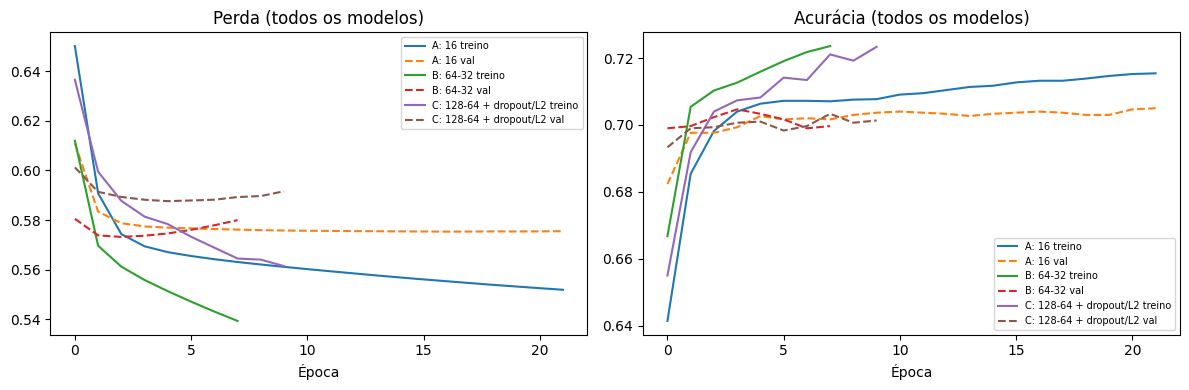

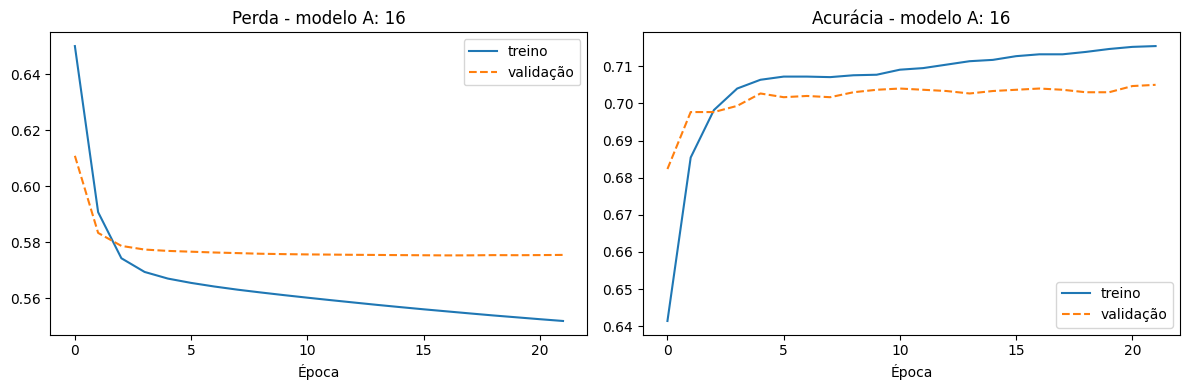

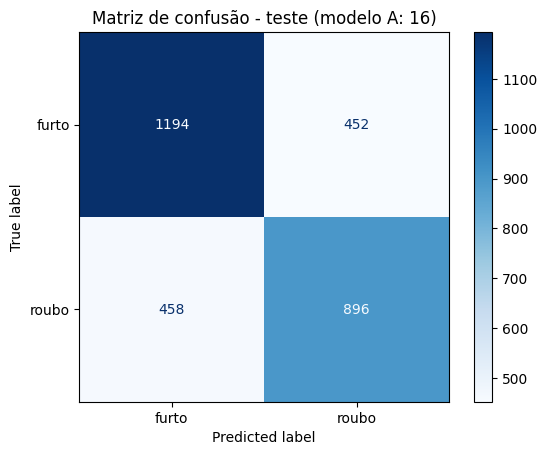

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, accuracy_score,
                             precision_score, recall_score, f1_score)

escolhido = "A: 16"
m = treinados[escolhido]


def get_hist(h):
    """Aceita objeto History do Keras ou dict simples."""
    return h.history if hasattr(h, "history") else h


def acc_key(hist):
    return "accuracy" if "accuracy" in hist else "acc"


# 1. Curvas de perda e acurácia (todos os modelos, para comparar)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for nome, h in historicos.items():
    hist = get_hist(h)
    k = acc_key(hist)
    ax[0].plot(hist["loss"], label=f"{nome} treino")
    ax[0].plot(hist["val_loss"], "--", label=f"{nome} val")
    ax[1].plot(hist[k], label=f"{nome} treino")
    ax[1].plot(hist["val_" + k], "--", label=f"{nome} val")
ax[0].set_title("Perda (todos os modelos)")
ax[1].set_title("Acurácia (todos os modelos)")
for a in ax:
    a.set_xlabel("Época")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

# 2. Curvas só do modelo escolhido (o que o slide 8 pede)
hist = get_hist(historicos[escolhido])
k = acc_key(hist)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["loss"], label="treino")
ax[0].plot(hist["val_loss"], "--", label="validação")
ax[0].set_title(f"Perda - modelo {escolhido}")
ax[1].plot(hist[k], label="treino")
ax[1].plot(hist["val_" + k], "--", label="validação")
ax[1].set_title(f"Acurácia - modelo {escolhido}")
for a in ax:
    a.set_xlabel("Época")
    a.legend()
plt.tight_layout()
plt.show()

prob_te = m.predict(X_te_p, verbose=0).ravel()
pred_te = (prob_te >= 0.5).astype(int)

# 4. Matriz de confusão (teste)
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te),
                       display_labels=["furto", "roubo"]).plot(cmap="Blues")
plt.title(f"Matriz de confusão - teste (modelo {escolhido})")
plt.show()

In [48]:
import joblib, tensorflow as tf, sklearn

m = treinados["A: 16"]
m.save("modelo_mlp.keras")
joblib.dump(enc, "encoder.joblib")      # o OneHotEncoder ajustado no treino

print("tensorflow", tf.__version__, "| scikit-learn", sklearn.__version__)

from google.colab import files
files.download("modelo_mlp.keras")
files.download("encoder.joblib")

tensorflow 2.21.0 | scikit-learn 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
import tensorflow as tf, sklearn, numpy, pandas, joblib
print("tensorflow", tf.__version__)
print("scikit-learn", sklearn.__version__)
print("numpy", numpy.__version__)
print("pandas", pandas.__version__)
print("joblib", joblib.__version__)

tensorflow 2.21.0
scikit-learn 1.6.1
numpy 2.4.6
pandas 2.2.3
joblib 1.6.0
